In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import spikeinterface.full as si
import spikeinterface.extractors as se
from spikeinterface.sortingcomponents.peak_detection import detect_peaks
from spikeinterface.sortingcomponents.peak_localization import localize_peaks
from pathlib import Path

# ---- CHANGE THESE TWO FOR A NEW PATIENT !!! ----
name = "NPIX_MSIT_014"
folder = Path(r"C:\Users\wongbe\Desktop\PROJECTS_PC\npix_data_bhw\2026-10-02_15-08-00_NPIX_MSIT_014")
# ---------------------------------------------------

# output folder for this exploratory code
out_dir = folder / f"{name}_raw_explore"
out_dir.mkdir(exist_ok=True)

# task computer's TTL log: search the session folder
# this will be used to align all plots/slices etc.. to the unified time base
ttl_logs = list(folder.rglob("*_TTL_log.txt"))
print(ttl_logs) # should be exactly one file
ttl_log_path = ttl_logs[0]

# load the recording
raw_AP = se.read_openephys(folder, stream_name="Record Node 123#OneBox-122.ProbeA-AP")
raw_LFP = se.read_openephys(folder, stream_name="Record Node 123#OneBox-122.ProbeA-LFP")
print(raw_AP)
print(raw_LFP)

# shared clock: time of the first sample of continuous.dat
t0 = raw_AP.get_start_time()
print(t0, raw_LFP.get_start_time())

# check SI's times match timestamps.npy (should be close to 0, which means no lost samples)
ts = np.load(folder / "Record Node 123" / "experiment1" / "recording1" / "continuous" / "OneBox-122.ProbeA-AP" / "timestamps.npy")
print(np.max(np.abs(ts - raw_AP.get_times())))

%matplotlib inline


[WindowsPath('C:/Users/wongbe/Desktop/PROJECTS_PC/npix_data_bhw/2026-10-02_15-08-00_NPIX_MSIT_014/NPX_MSIT_014_taskdata_good/NPX_MSIT_014_second_2026-10-02_15H_23m_51s_TTL_log.txt')]
OpenEphysBinaryRecordingExtractor: 384 channels - 30.0kHz - 1 segments - 48,159,900 samples 
                                   1,605.33s (26.76 minutes) - int16 dtype - 34.45 GiB
OpenEphysBinaryRecordingExtractor: 384 channels - 2500.0Hz - 1 segments - 4,013,325 samples 
                                   1,605.33s (26.76 minutes) - int16 dtype - 2.87 GiB
72.2996 72.2996
1.4642864698544145e-10


In [2]:
# start time for MSIT_014 in this example is 72.3 seconds, so we will keep this in mind
# now band pass filter 300-3000 Hz for AP
AP_high = si.bandpass_filter(raw_AP, freq_min=300, freq_max=3000, margin_ms=20)

In [3]:
# phase shift and Common MEDIAN Reference
AP_phasecorrect = si.phase_shift(recording=AP_high)  # phase correct the recording

AP_CMR = si.common_reference(recording=AP_phasecorrect)

print(AP_CMR)


CommonReferenceRecording: 384 channels - 30.0kHz - 1 segments - 48,159,900 samples 
                          1,605.33s (26.76 minutes) - int16 dtype - 34.45 GiB


In [4]:
# get noise levels

AP_noise = si.get_noise_levels(AP_CMR, return_in_uV=False) # we do not want uV because detect_peaks uses raw ADC units

noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

In [5]:
# detect peaks
# locally_exclusive means if one spike shows up on several nearby (50um radius) channels, it keeps only biggest
# Threshold is 5x the noise noise and 50um radius
# n_jobs is parallel jobs, can probs go more than 8, and chunk_duration is how long each chunk, can also maybe go up
AP_peaks = detect_peaks(recording=AP_CMR, method="locally_exclusive", 
                        noise_levels=AP_noise, detect_threshold=5, radius_um=50, n_jobs=16, chunk_duration="2s", progress_bar=True)

print(len(AP_peaks))

c:\Users\wongbe\Desktop\PROJECTS_PC\bhw_code\neuro-env-pc.venv\Lib\site-packages\spikeinterface\sortingcomponents\peak_detection\main.py:60: UserWarning: The signature of detect_peaks() has changed, now method_kwargs and job_kwargs are dinstinct params.This warning will raise an error in version 0.105.0
  warnings.warn(


detect peaks (locally_exclusive) (workers: 16 processes spawn):   0%|          | 0/803 [00:00<?, ?it/s]

1064845


In [6]:
# save AP_peaks to a file

np.save(out_dir /  f"{name}_AP_peaks.npy", AP_peaks)


In [7]:
print(AP_peaks[:5]) # print first 5 peaks
# output format is sample_index (this is the sample number, not the time, so e.g. the 221st sample is VERY early)
# then channel index (channel number)
# then amplitude (in raw ADC units), then segment index (here it's only 0 b/c only one segment)



[(200, 175, -128., 0) (221,  64, -857., 0) (221,  75, -856., 0)
 (231, 191, -633., 0) (232, 175, -279., 0)]


In [8]:
# center of mass means use the amplitude weighted average pos. of the spike across nearby channels
AP_peak_locations = localize_peaks(recording=AP_CMR, peaks=AP_peaks, method="center_of_mass", n_jobs=16, chunk_duration="2s", progress_bar=True)
print(AP_peak_locations[:5]) # print first 5 peak locations

# output format is x, y in um, where x is position across shank's width, which we don't use here, and y is the depth.

c:\Users\wongbe\Desktop\PROJECTS_PC\bhw_code\neuro-env-pc.venv\Lib\site-packages\spikeinterface\sortingcomponents\peak_localization\main.py:116: UserWarning: The signature of localize_peaks() has changed, now method_kwargs and job_kwargs are dinstinct params.This warning will raise an error in version 0.105.0
  warnings.warn(


localize peaks (center_of_mass) (workers: 16 processes spawn):   0%|          | 0/803 [00:00<?, ?it/s]

[(17.32538105, 1741.57720345) ( 5.88917133,  636.92933401)
 (26.20400381,  744.01334604) (25.96226415, 1899.23670669)
 (15.78785076, 1741.17175455)]


Text(0, 0.5, 'depth (um)')

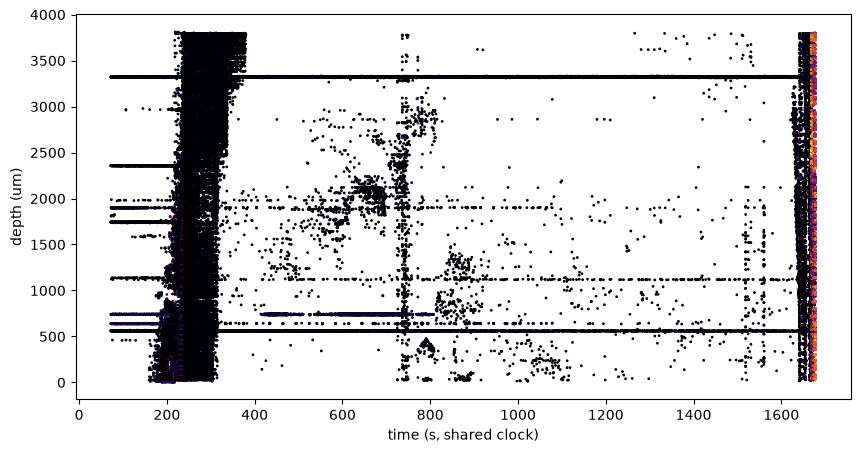

In [9]:
# plot a raster of peaks on the shared clock
peak_t_all = AP_CMR.sample_index_to_time(AP_peaks["sample_index"])  # shared clock, seconds
d = slice(None, None, 5)  # every 5th peak

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(peak_t_all[d], AP_peak_locations["y"][d], c=AP_peaks["amplitude"][d], cmap="inferno_r", s=1)
ax.set_xlabel("time (s, shared clock)")
ax.set_ylabel("depth (um)")



If the raster looks bad at first, it may be becasue of how get_noise_levels works: it picks 20 random 0.5s bins to base noise on, so sometimes you end up with a very high noise estimate if the probe insertion happens to be included in the noise estimate. If this is the case, we can slice for just when the trial is actually happening and base nosie on that, which we do in the next few cells. You'll see that there is a high median from AP_noise and a lower median from AP_segment_noise if this is the case. 

In [10]:
# if few units initially, possible that insertion/removal of probe are messing with noise levels
# slice to just from trial start to trial end, based on task TTLs (the shared clock)

events = se.read_openephys_event(folder).get_events("OneBox ADC Digital Lines") # spike interface calls it this for some reason, it's the folder events\OneBox-122.OneBox-ADC\TTL
task_pulses = events["time"][events["label"] == "5"] # line 5 = task TTLs (line 1 = 1 Hz sync)

task_log_df = pd.read_table(ttl_log_path, sep=r"\s+") # task computer list of events, there is one row per pulse it sends. pd.read_table makes a copy of the log

## basically, the task_log from the task computer has a list of events, but no times. The task_pulses are recorded by OEphys, with unified time, but do not have event names.
# so we have to match task_log and task_pulses
task_log_df["npix_time"] = task_pulses[-len(task_log_df):] # last (len) pulses = the (len) rows of the log

trial_start = task_log_df.npix_time[task_log_df.Event == "Fixation_Shown"].iloc[0]
trial_end = task_log_df.npix_time[task_log_df.Event == "Trial_Data_Stored"].iloc[-1]
print(trial_start, trial_end)



982.5070630898542 1614.223793494684


In [11]:
# check median noise level from before
print(np.median(AP_noise))

# noise during the trials only (first trial to last trial, shared clock, from the TTL cell above)
AP_segment = AP_CMR.frame_slice(start_frame=AP_CMR.time_to_sample_index(trial_start),
                                end_frame=AP_CMR.time_to_sample_index(trial_end))

AP_segment_noise = si.get_noise_levels(AP_segment, return_in_uV=False)
print(np.median(AP_segment_noise))

30.46747559029012


noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

24.61119682719299


In [12]:
# now make new peaks from the new noise
AP_peaks_new_noise = detect_peaks(recording=AP_CMR, method="locally_exclusive", 
                        noise_levels=AP_segment_noise, detect_threshold=5, radius_um=50, n_jobs=16, chunk_duration="2s", progress_bar=True)

print(len(AP_peaks_new_noise))

c:\Users\wongbe\Desktop\PROJECTS_PC\bhw_code\neuro-env-pc.venv\Lib\site-packages\spikeinterface\sortingcomponents\peak_detection\main.py:60: UserWarning: The signature of detect_peaks() has changed, now method_kwargs and job_kwargs are dinstinct params.This warning will raise an error in version 0.105.0
  warnings.warn(


detect peaks (locally_exclusive) (workers: 16 processes spawn):   0%|          | 0/803 [00:00<?, ?it/s]

1890543


In [13]:
np.save(out_dir /  f"{name}_AP_peaks_new_noise.npy", AP_peaks_new_noise)

print(AP_peaks_new_noise[:5]) # recall this prints sample_index, channel_index, amplitude (in ADC units), segment_index


AP_peaks_new_noise_locations = localize_peaks(recording=AP_CMR, peaks=AP_peaks_new_noise, method="center_of_mass", n_jobs=16, chunk_duration="2s", progress_bar=True)
print(AP_peaks_new_noise_locations[:5])


[(  4, 56, -203., 0) ( 64, 56, -194., 0) (115, 56, -187., 0)
 (137, 75, -158., 0) (177, 56, -174., 0)]


c:\Users\wongbe\Desktop\PROJECTS_PC\bhw_code\neuro-env-pc.venv\Lib\site-packages\spikeinterface\sortingcomponents\peak_localization\main.py:116: UserWarning: The signature of localize_peaks() has changed, now method_kwargs and job_kwargs are dinstinct params.This warning will raise an error in version 0.105.0
  warnings.warn(


localize peaks (center_of_mass) (workers: 16 processes spawn):   0%|          | 0/803 [00:00<?, ?it/s]

[( 9.92513369, 560.80213904) (11.95128552, 560.51420839)
 (11.71726535, 561.34414832) (16.85164213, 740.6795017 )
 (10.65478842, 558.08463252)]


Text(0.5, 1.0, 'Trial window')

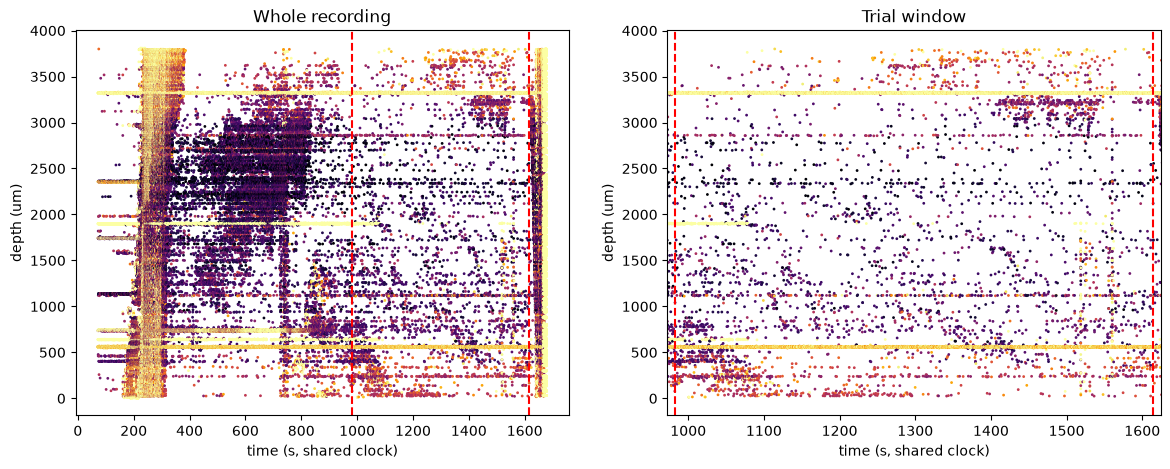

In [14]:
peak_t = AP_CMR.sample_index_to_time(AP_peaks_new_noise["sample_index"]) # shared clock (seconds)
d = slice(None, None, 5)  # every 5th peak

fig, axes = plt.subplots(1, 2, figsize=(14, 5)) # 1 row, 2 panels side by side

for ax in axes: # same raster in both panels, color amplitude, clim set for a better color gradient
    ax.scatter(peak_t[d], AP_peaks_new_noise_locations["y"][d], c=AP_peaks_new_noise["amplitude"][d],
               cmap="inferno_r", vmin=-200, vmax=-100, s=1)
    ax.axvline(trial_start, color="red", linestyle="--")   # first trial (from TTLs)
    ax.axvline(trial_end, color="red", linestyle="--")     # last trial (from TTLs)
    ax.set_xlabel("time (s, shared clock)")
    ax.set_ylabel("depth (um)")

axes[0].set_title("Whole recording")
axes[1].set_xlim(trial_start - 10, trial_end + 10)
axes[1].set_title("Trial window")



Next we are going to try to plot the ~30 largest amplitude peaks, but we need to remove bad ones from candidates. We'll first use si.detect_bad_channels

In [15]:
# find bad channels to remove from candidates below
AP_task_hp = AP_task_hp = AP_phasecorrect.frame_slice(start_frame=AP_phasecorrect.time_to_sample_index(trial_start),
                                         end_frame=AP_phasecorrect.time_to_sample_index(trial_end))

bad_ids, labels = si.detect_bad_channels(AP_task_hp)
print(bad_ids)
print(labels)


['AP64' 'AP191']
['good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'dead' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good'
 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'good' 'go

MSIT014: exclude 64, 191 based on the si.detect_bad_channels

In [16]:
# plotting traces with the few highest amplitude peaks within the task window
t = AP_peaks_new_noise["sample_index"] / 30000 # file time in s

###### Add any channels you determine are bad here ######----------------------
my_bad = ["AP252", "AP383", "AP249", "AP254"]   # added by eye from the 30-panel grid, MSIT014 (change these to what you find)

exclude = np.concatenate([bad_ids, my_bad])   # detect_bad_channels + mine
keep = (t > trial_start) & (t < trial_end) & ~np.isin(AP_CMR.channel_ids[AP_peaks_new_noise["channel_index"]], exclude)

candidates = np.where(keep)[0]
cand = candidates[np.argsort(AP_peaks_new_noise["amplitude"][candidates])][:30]  # 30 biggest


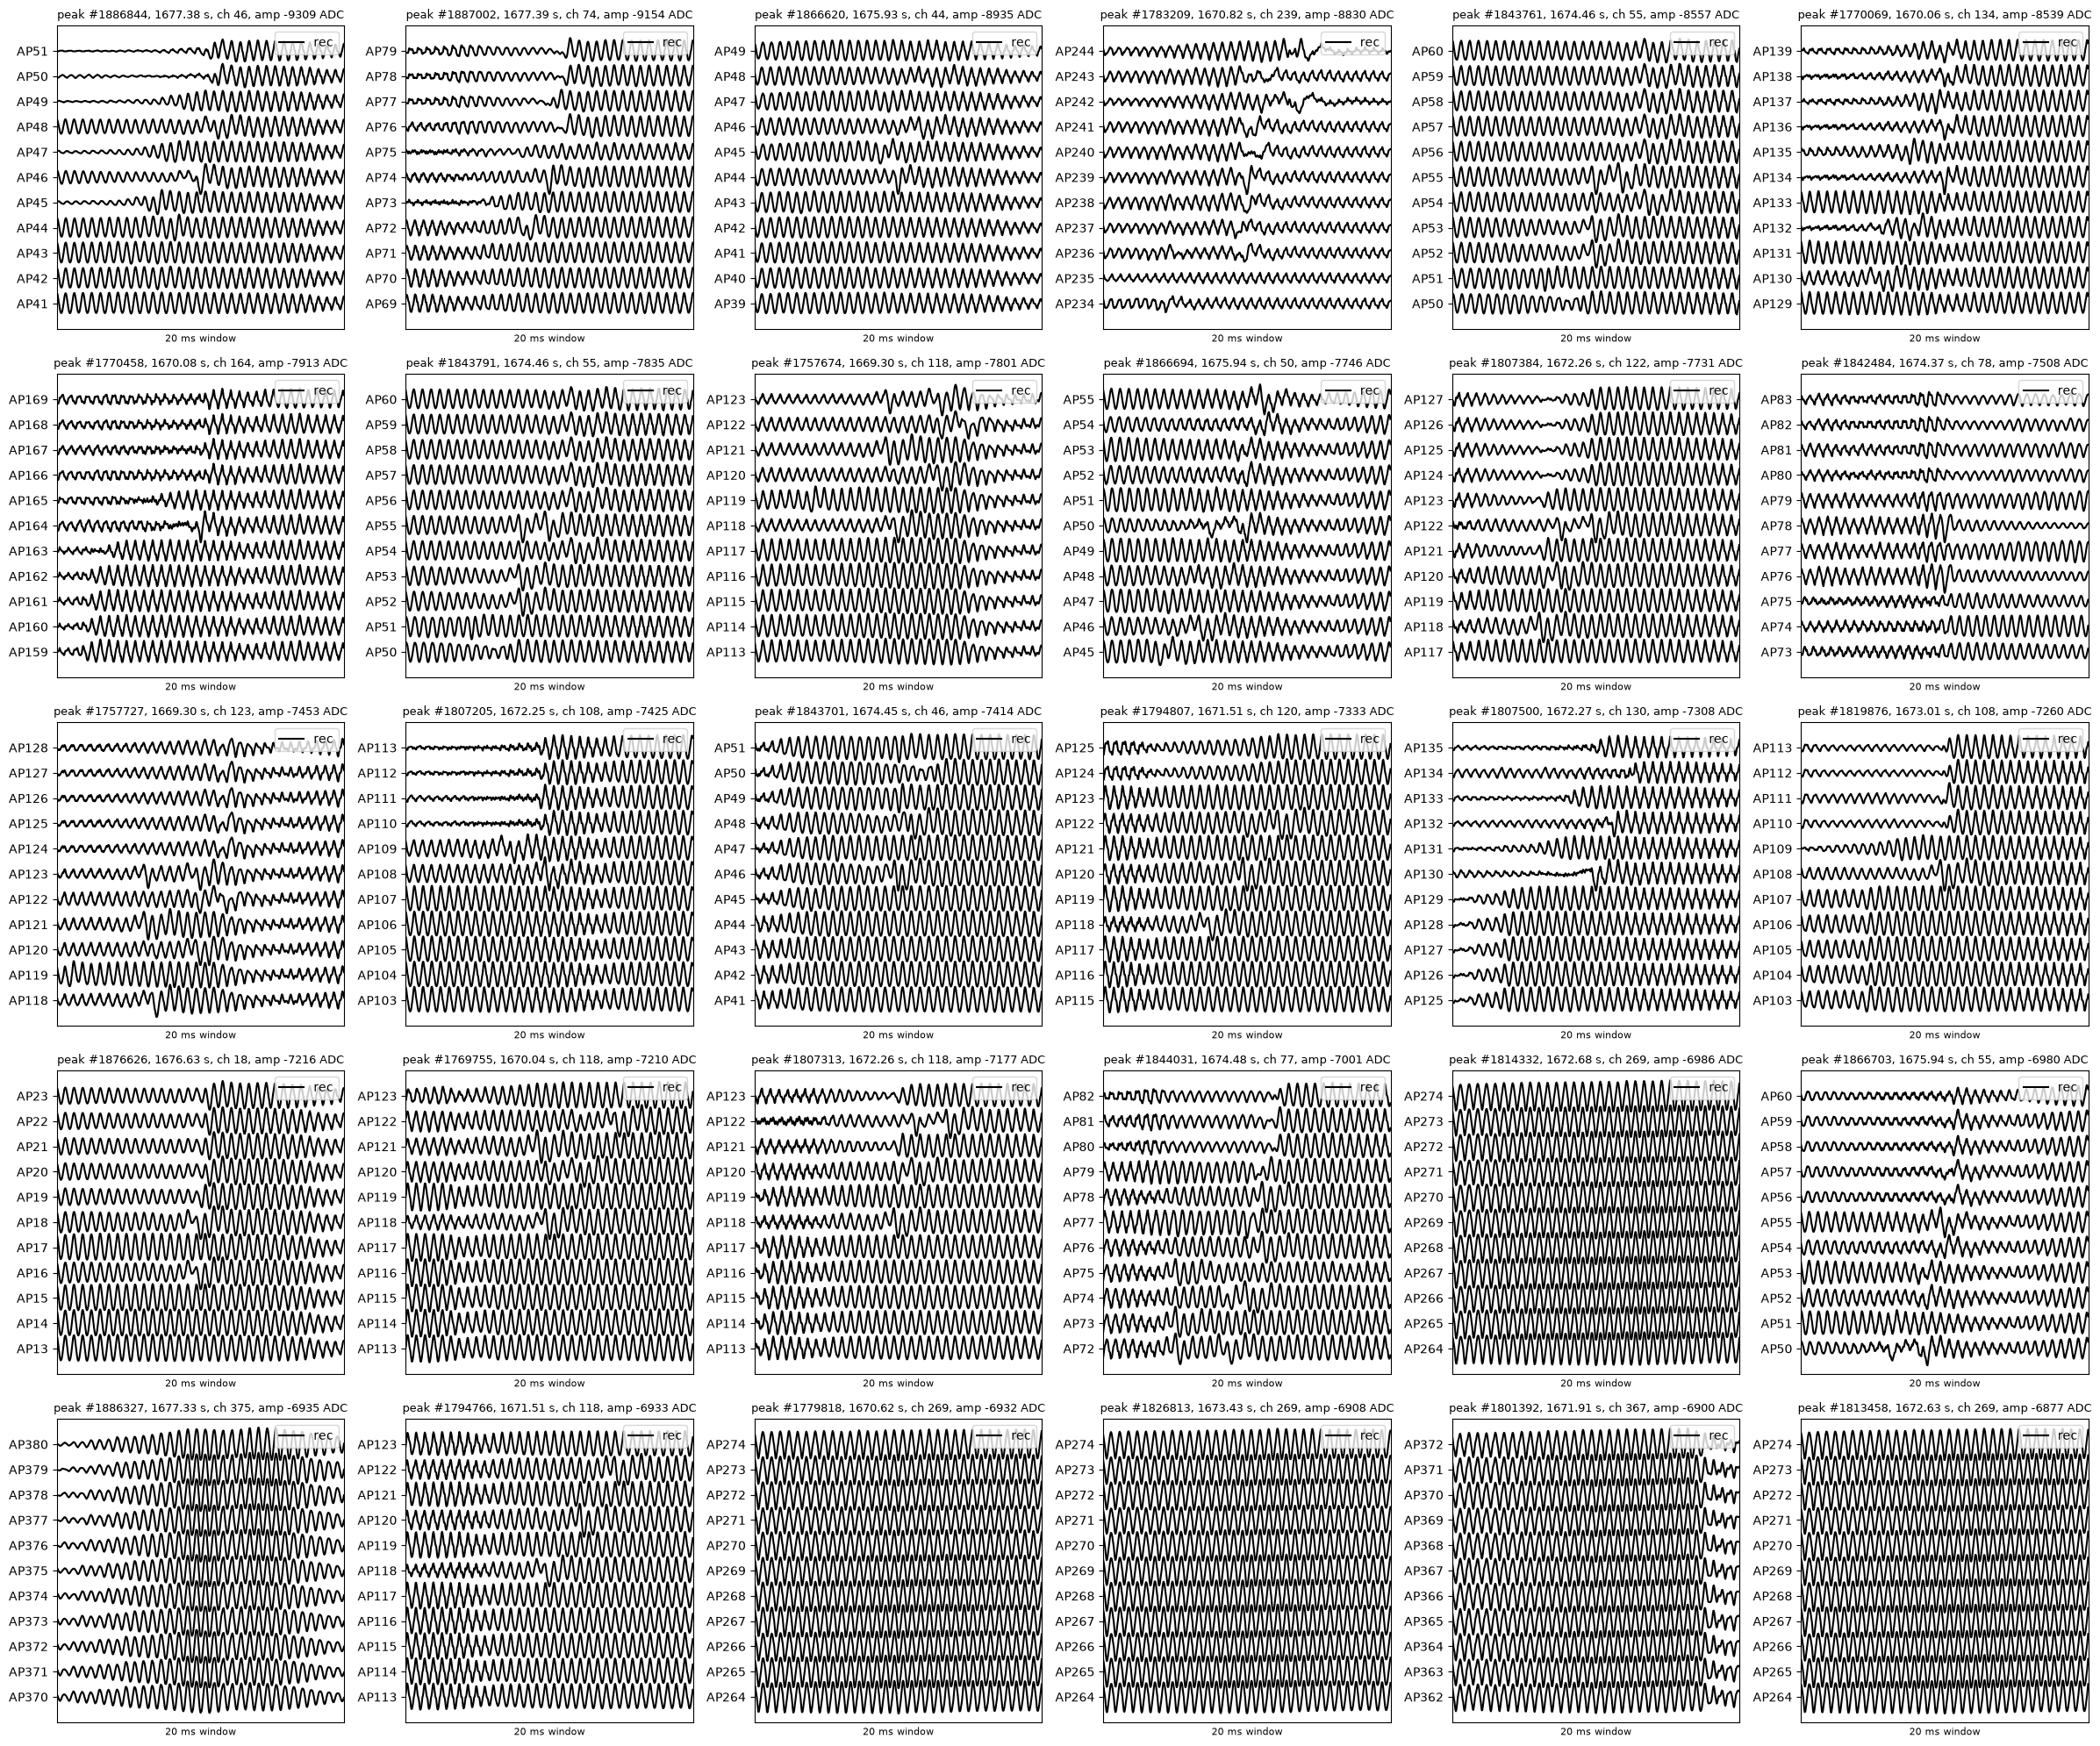

In [17]:
%matplotlib inline
plt.close("all")   # clear old figures so only this grid shows


fig, axes = plt.subplots(5, 6, figsize=(24, 20)) # 5 rows x 6 columns = 30 panels

for ax, i in zip(axes.flat, cand[:30]): # pairs each panel with one candidate
    s  = AP_peaks_new_noise["sample_index"][i]  # spike sample
    ch = AP_peaks_new_noise["channel_index"][i] # spike channel
    t_spike = AP_CMR.sample_index_to_time(s)    # shared clock, s

    si.plot_traces(AP_CMR, channel_ids=AP_CMR.channel_ids[max(ch-5, 0):ch+6],
                   time_range=(t_spike - 0.01, t_spike + 0.01),
                   backend="matplotlib", show_channel_ids=True, ax=ax)
    ax.set_title(f"peak #{i}, {t_spike:.2f} s, ch {ch}, amp {AP_peaks_new_noise['amplitude'][i]:.0f} ADC", fontsize=9)
    # peak numbers are from AP_peaks_new_noise
    ax.set_xticks([])  # remove the overlapping time labels
    ax.set_xlabel("20 ms window", fontsize=8)

fig.tight_layout()




^ this way isn't really working so instead we will just use a si.plot_traces widget and manually scroll through to find spikes.

In [18]:

%matplotlib widget
w = si.plot_traces(AP_CMR, backend="ipywidgets",
                   channel_ids=AP_CMR.channel_ids[0:20],
                   time_range=(trial_start, trial_start + 1))  # shared clock, s: opens at the first trial



AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

![alt text]({F14BB750-260E-4339-9BA3-8208B4160902}.png) # this is a good example from MSIT014 at time 885.7 (unified/npix time) in the first 6 channels




again at 910s:
![alt text]({ACF5ECFA-9EB7-4FBC-9B79-3B8C5382E38A}.png)

In [21]:
# Find channels based on depth. 
locs = raw_AP.get_channel_locations()
y = locs[:, 1] # height above tip, um

depth = 1300 # um
chans = np.where(np.abs(y - depth) < 40)[0]  # channels within 20 um of that depth
print(chans)



[128 129 130 131 132 133]
